# 02 · Comparar, optimizar y validar modelos de ML

**Objetivo:** elegir un modelo y un umbral usando validación, evaluar una prueba temporal reservada y guardar el mismo pipeline que usarán los scripts y la app.

**Tiempo de práctica: 25 minutos.** Se comparan una referencia trivial, regresión logística y boosting. La optimización está acotada a dos configuraciones adicionales para caber en el taller; no equivale a una búsqueda exhaustiva.

## Preparación
Ejecute primero el notebook 01. Seleccione el kernel `.venv`.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
assert (ROOT / 'data/transacciones.parquet').exists(), 'Abra el repositorio y seleccione .venv'
sys.path.insert(0, str(ROOT / 'python'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
from taller import *
print('Repositorio:', ROOT.name)


Repositorio: taller_codex_compensar_ufa


In [2]:
from entrenar import compare_models, optimize, evaluate_and_save
base = pd.read_parquet(ROOT/'artifacts/base_modelo.parquet')
train, valid, test = temporal_split(base)
display(pd.DataFrame([{'particion':n,'filas':len(d),'desde':d.fecha_hora.min(),'hasta':d.fecha_hora.max(),
                      'ultima_etiqueta':d.fecha_cierre.max(),'tasa_fraude':d.es_fraude.mean()}
                     for n,d in [('entrenamiento',train),('validacion',valid),('prueba',test)]]))

,particion,filas,desde,hasta,ultima_etiqueta,tasa_fraude
0,entrenamiento,59896,2026-01-01 00:05:46,2026-03-29 14:22:30,2026-03-31 23:54:02,0.366585
1,validacion,33349,2026-04-01 00:00:13,2026-04-30 23:59:02,2026-06-14 23:58:01,0.236859
2,prueba,16728,2026-06-16 00:01:11,2026-06-30 23:59:51,2026-08-14 23:59:40,0.238821


## 1. Respetar el tiempo y la maduración
- Entrenamiento: compras anteriores al 1 de abril cuya investigación/ventana ya había cerrado antes de esa fecha.
- Validación: compras de abril, con etiquetas maduras antes del 16 de junio.
- Prueba: compras del 16 al 30 de junio, evaluadas retrospectivamente con etiquetas consolidadas el 15 de agosto.

Las compras no incluidas en estas particiones siguen siendo historia disponible para las variables de comportamiento. La selección por maduración cambia la prevalencia del entrenamiento; compare las tasas mostradas. No usamos IDs, género, pérdida confirmada, estado de investigación ni fecha de cierre como predictores.

Esta evaluación mide nuevas compras de la cartera conocida. No demuestra generalización a clientes nuevos.

In [3]:
prohibidas={'es_fraude','fecha_cierre','perdida_confirmada_cop','estado_caso','id_cliente','id_transaccion','genero'}
assert not set(FEATURES)&prohibidas
assert train.fecha_cierre.max()<pd.Timestamp('2026-04-01')
assert valid.fecha_cierre.max()<pd.Timestamp('2026-06-16')
print('Predictores:', FEATURES)
display(make_pipeline('logistica'))

Predictores: ['monto_cop', 'hora_dia', 'es_fin_semana', 'numero_cuotas', 'uso_3ds', 'es_internacional', 'fuera_ciudad', 'dispositivo_nuevo', 'comercio_nuevo', 'compras_previas_1h', 'monto_previo_24h', 'media_monto_previo', 'ratio_monto_historico', 'minutos_desde_anterior', 'cupo_tarjeta_cop', 'antiguedad_tarjeta_meses', 'score_crediticio', 'utilizacion_cupo_tarjetas', 'canal', 'categoria_comercio', 'metodo_autenticacion']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

## 2. Comparar con una referencia
El pipeline aprende imputación, escalado y categorías solamente con entrenamiento. Average Precision resume la curva precisión–recall mediante saltos de recall; no es la integral trapezoidal de esa curva. El modelo trivial ayuda a interpretar la mejora sobre la prevalencia.

También medimos ROC-AUC, precisión, recall y Brier. Las métricas de clasificación iniciales usan 0,5; el umbral operativo se definirá después.

In [4]:
fitted, comparacion = compare_models(train, valid)
display(comparacion[['modelo','average_precision','roc_auc','precision','recall','segundos']].round(4))

,modelo,average_precision,roc_auc,precision,recall,segundos
0,Dummy,0.2369,0.5000,0.0000,0.0000,1.0702
1,Logistica,0.5461,0.7729,0.5717,0.4371,1.1501
2,Boosting_base,0.5832,0.7969,0.5564,0.5277,5.5249


## 3. Optimizar sin tocar prueba
Dos configuraciones de boosting modifican hojas y regularización. Elegimos la mayor Average Precision en la misma validación; este uso repetido puede sobreajustar validación, por eso prueba permanece reservada.

El presupuesto de alertas es un supuesto didáctico: aproximadamente 20% en validación. El umbral resultante no garantiza el mismo volumen en otros periodos.

,modelo,average_precision,roc_auc,segundos
3,Boosting_15,0.5854,0.7980,3.9522
4,Boosting_31,0.5834,0.7965,5.5038
2,Boosting_base,0.5832,0.7969,5.5249
1,Logistica,0.5461,0.7729,1.1501
0,Dummy,0.2369,0.5000,1.0702


Ganador por validación: Boosting_15 | Umbral: 0.5299


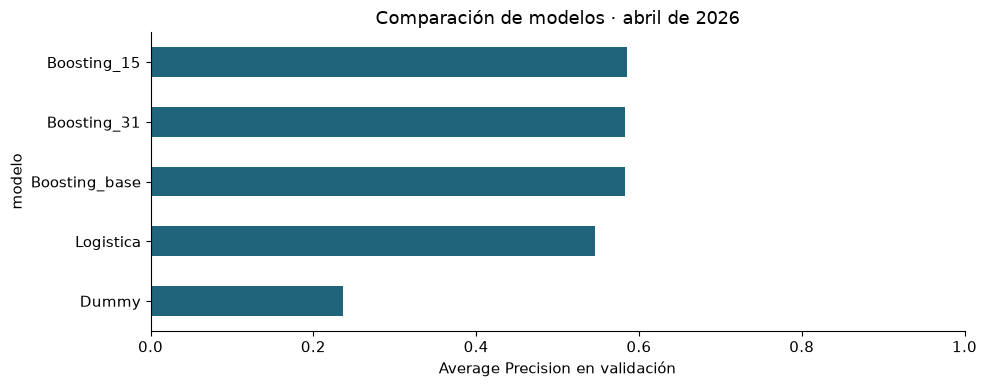

In [5]:
modelo, ganador, umbral, comparacion = optimize(train, valid, fitted, comparacion)
display(comparacion[['modelo','average_precision','roc_auc','segundos']].round(4))
print('Ganador por validación:', ganador, '| Umbral:', round(umbral,4))
comparacion.sort_values('average_precision').plot.barh(x='modelo',y='average_precision',legend=False,color='#20647c')
plt.xlabel('Average Precision en validación'); plt.xlim(0,1); plt.title('Comparación de modelos · abril de 2026'); plt.tight_layout(); plt.show()

## 4. Evaluar prueba una sola vez
Congelamos modelo, predictores y umbral. La matriz permite distinguir falsos positivos —revisiones innecesarias— y falsos negativos —fraudes no alertados—. No cambiamos el modelo a partir de este resultado.

,prueba
n,16728.000000
prevalencia,0.238821
average_precision,0.597834
roc_auc,0.800958
precision,0.589129
recall,0.504631
f1,0.543616
brier,0.146330
tasa_alertas,0.204567


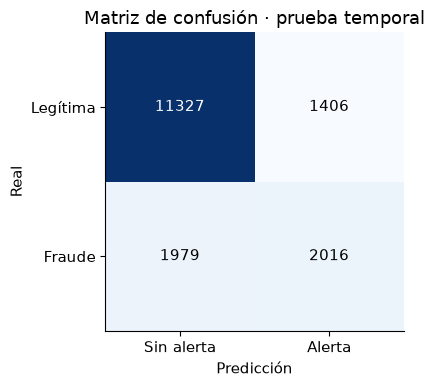

In [6]:
metricas, importancias, predicciones = evaluate_and_save(modelo, ganador, umbral, comparacion, train, valid, test)
display(pd.Series({k:v for k,v in metricas['prueba'].items() if k!='matriz_confusion'},name='prueba').to_frame())
matriz=np.array(metricas['prueba']['matriz_confusion'])
fig,ax=plt.subplots(figsize=(5,4)); ax.imshow(matriz,cmap='Blues')
for i in range(2):
    for j in range(2): ax.text(j,i,str(matriz[i,j]),ha='center',va='center',color='white' if matriz[i,j]>matriz.max()/2 else 'black')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Sin alerta','Alerta'],yticklabels=['Legítima','Fraude'],xlabel='Predicción',ylabel='Real',title='Matriz de confusión · prueba temporal')
plt.tight_layout(); plt.show()

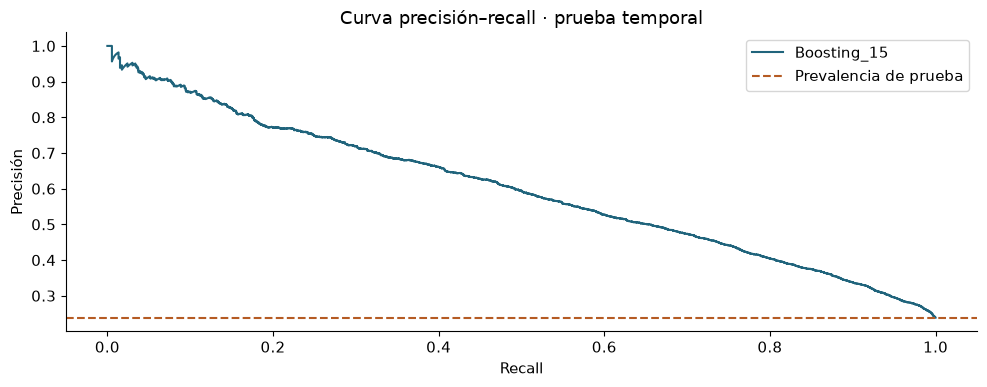

In [7]:
from sklearn.metrics import precision_recall_curve
precision,recall,_=precision_recall_curve(predicciones.es_fraude,predicciones.riesgo_estimado)
plt.plot(recall,precision,color='#20647c',label=ganador)
plt.axhline(predicciones.es_fraude.mean(),color='#b55b23',linestyle='--',label='Prevalencia de prueba')
plt.xlabel('Recall'); plt.ylabel('Precisión'); plt.title('Curva precisión–recall · prueba temporal'); plt.legend(); plt.tight_layout(); plt.show()

## 5. Explicar el modelo
La importancia por permutación mide cuánto empeora Average Precision al desordenar una variable, manteniendo las demás. Usamos 2.000 compras de validación y tres repeticiones para limitar tiempo. La desviación refleja variación entre permutaciones, no un intervalo de confianza poblacional.

Las variables correlacionadas pueden compartir señal y aparentar menor importancia. Esto explica dependencia del modelo; no demuestra causas del fraude.

,variable,importancia_media,desviacion
12,ratio_monto_historico,0.1722,0.0157
7,dispositivo_nuevo,0.0464,0.0106
20,metodo_autenticacion,0.0441,0.0038
1,hora_dia,0.0335,0.0034
13,minutos_desde_anterior,0.0319,0.0040
6,fuera_ciudad,0.0152,0.0032
5,es_internacional,0.0079,0.0028
11,media_monto_previo,0.0018,0.0010
0,monto_cop,0.0017,0.0022
3,numero_cuotas,0.0002,0.0002


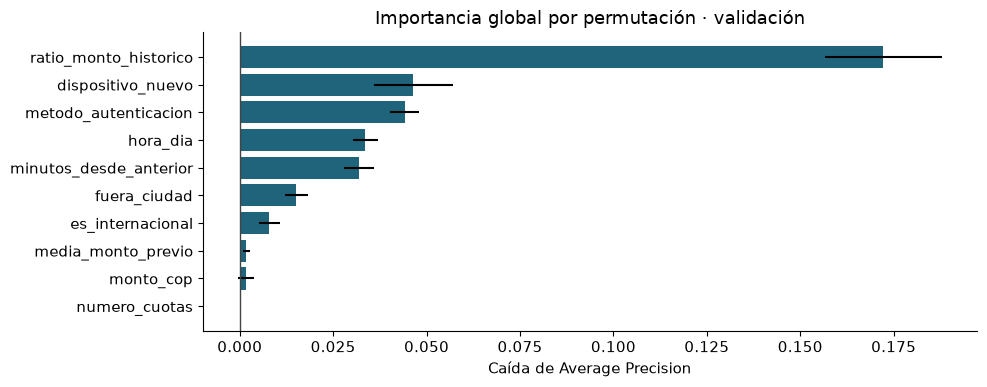

In [8]:
display(importancias.head(10).round(4))
top=importancias.head(10).sort_values('importancia_media')
plt.barh(top.variable,top.importancia_media,xerr=top.desviacion,color='#20647c')
plt.axvline(0,color='#444',linewidth=1); plt.xlabel('Caída de Average Precision'); plt.title('Importancia global por permutación · validación'); plt.tight_layout(); plt.show()

## 6. Verificar la inferencia y priorizar clientes
El pipeline serializado debe devolver los mismos resultados que el modelo en memoria. La prioridad combina número de alertas y riesgo máximo observado; ese máximo no es una probabilidad de fraude del cliente.

In [9]:
bundle=load_model()
recalculadas=predict_features(test,bundle)
assert np.allclose(recalculadas.riesgo_estimado,predicciones.riesgo_estimado)
assert recalculadas.riesgo_estimado.between(0,1).all()
assert set(recalculadas.alerta.unique())<={0,1}
display(rank_customers(recalculadas).head(10))
print('Artefacto listo:', ROOT/'artifacts/modelo_fraude.joblib')

,id_cliente,riesgo_maximo,alertas,transacciones,monto_observado_cop
0,CLI00356,0.919341,10,29,4331353.76
1,CLI04923,0.829786,9,22,9422949.75
2,CLI04963,0.910162,8,10,1285119.37
3,CLI03633,0.836355,8,30,11521474.61
4,CLI01469,0.923132,7,15,5807071.31
5,CLI03716,0.908390,7,18,7326472.78
6,CLI02339,0.900007,7,9,2744419.83
7,CLI03358,0.942314,6,7,1469710.81
8,CLI02045,0.912542,6,30,5753616.70
9,CLI01701,0.909439,6,10,3000507.59


Artefacto listo: C:\Users\cgara\Documents\Repos\taller_codex_compensar_ufa\artifacts\modelo_fraude.joblib


## Entrega y continuación
Abra `guia/index.html` para ejecutar el script por lotes, preparar la tarea de Windows, regenerar el reporte y probar Streamlit/API.

**Evidencia individual:** comparación de modelos, matriz de prueba, tres variables relevantes y una justificación del umbral. Añada una limitación: prevalencia artificial, etiquetas maduras, clientes conocidos o incertidumbre de calibración.

**Prompt para Codex:** «Audita este pipeline. Verifica que imputación y codificación se ajusten solo con entrenamiento, que la selección no use prueba y que el artefacto serializado mantenga las predicciones. Ejecuta las pruebas y explica cualquier fallo».

El entrenamiento y la inferencia son una demostración local. Un despliegue real requiere monitoreo, versionado de datos, control de acceso, estado histórico persistente y validación con datos representativos.